# Lab 05 — Image Segmentation


## Setup

In [ ]:
import os
import textwrap
from collections import deque

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("outputs", exist_ok=True)   # final outputs of every task are saved here

def load(name, flag=cv2.IMREAD_COLOR):
    img = cv2.imread(os.path.join("images", name), flag)
    if img is None:
        raise FileNotFoundError(f"Could not read images/{name}")
    return img

def show_row(images, titles, out_name, caption=None, figsize=None):
    """Display images in one row, save the figure to outputs/."""
    n = len(images)
    fig, axes = plt.subplots(1, n, figsize=figsize or (3.2 * n, 4))
    axes = [axes] if n == 1 else list(axes)
    for ax, im, t in zip(axes, images, titles):
        if im.ndim == 3:
            ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(im, cmap="gray", vmin=0, vmax=255)
        ax.set_title(t, fontsize=9)
        ax.axis("off")
    if caption:
        fig.text(0.5, 0.01, textwrap.fill(caption, 150), ha="center", fontsize=9)
    plt.tight_layout(rect=(0, 0.1 if caption else 0, 1, 1))
    plt.savefig(os.path.join("outputs", out_name), dpi=150)
    plt.show()

# Task 1 — Automated Inspection of a Document Under Uneven Lighting

## 1. Load image in grayscale

In [ ]:
gray = load("sudoku.png", cv2.IMREAD_GRAYSCALE)
print(gray.shape)

(563, 558)


## 2–3. Global thresholding with three values and compare masks
Text is dark, so `THRESH_BINARY_INV` turns text white. T = 50 / 80 / 110 (low / medium / high).

In [ ]:
T = [50, 80, 110]
global_masks = [cv2.threshold(gray, t, 255, cv2.THRESH_BINARY_INV)[1] for t in T]
for t, m in zip(T, global_masks):
    print(f"Global T={t}: white pixels = {100 * (m > 0).mean():.1f}%")

Global T=50: white pixels = 8.3%
Global T=80: white pixels = 25.8%
Global T=110: white pixels = 57.3%


## 4. Adaptive thresholding
Parameters: Gaussian method, **blockSize = 21** (large enough to cover a digit stroke), **C = 10** (suppresses paper noise).

In [ ]:
adaptive = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                 cv2.THRESH_BINARY_INV, 21, 10)
print(f"Adaptive: white pixels = {100 * (adaptive > 0).mean():.1f}%")

Adaptive: white pixels = 14.0%


## 5–7. Comparison  (Original → Global T1 → T2 → T3 → Adaptive)

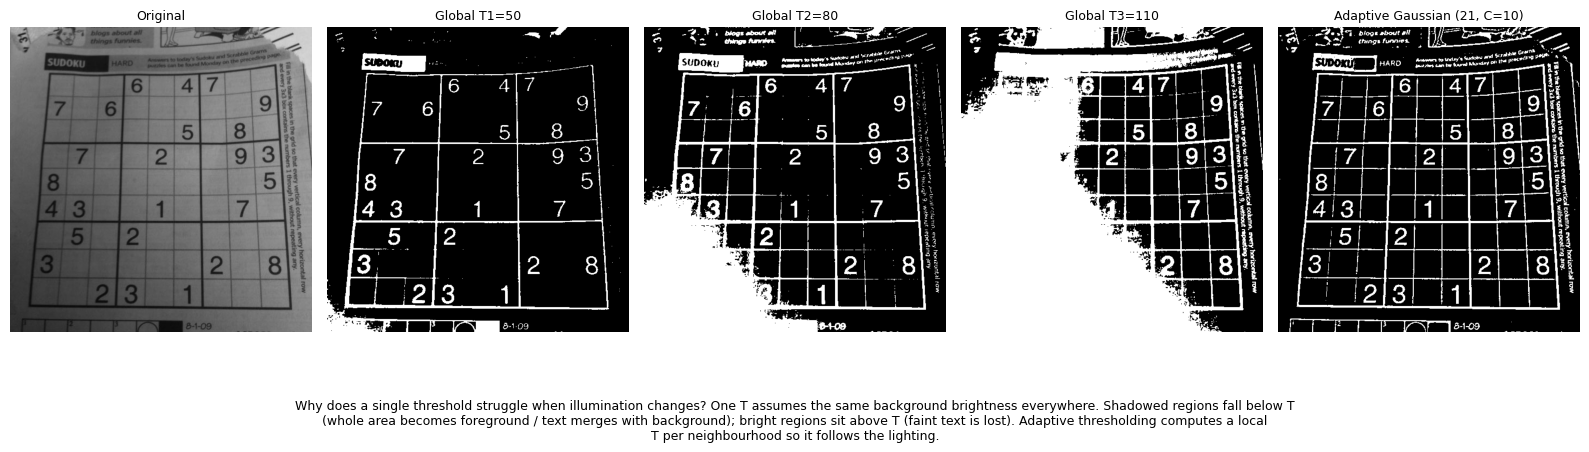

True

In [ ]:
caption = ("Why does a single threshold struggle when illumination changes? One T assumes the same background brightness everywhere. "
           "Shadowed regions fall below T (whole area becomes foreground / text merges with background); bright regions sit above T "
           "(faint text is lost). Adaptive thresholding computes a local T per neighbourhood so it follows the lighting.")
show_row([gray] + global_masks + [adaptive],
         ["Original"] + [f"Global T{i+1}={t}" for i, t in enumerate(T)] + ["Adaptive Gaussian (21, C=10)"],
         "task01_result.png", caption, figsize=(16, 4.8))
cv2.imwrite("outputs/task01_final_adaptive_mask.png", adaptive)

## Observations
* **Regions that make global thresholding fail:** the left/bottom-left shadowed area and the dark page edges (turn white at higher T), and the bright top/right area (digits vanish at low T).
* **Best parameters:** Adaptive Gaussian, blockSize 21, C 10 — digits and grid lines are kept uniformly across the page.

# Task 2 — Choosing the Correct Adaptive Threshold Strategy

In [ ]:
gray = load("sudoku.png", cv2.IMREAD_GRAYSCALE)

## Parameter grid
blockSize ∈ {5, 21, 71} (small / medium / large, must be odd) × C ∈ {2, 10, 25} × method ∈ {Mean, Gaussian}.

Mean     block=  5 C= 2  white pixels =  22.2%
Mean     block=  5 C=10  white pixels =   9.3%
Mean     block=  5 C=25  white pixels =   1.6%
Mean     block= 21 C= 2  white pixels =  25.5%
Mean     block= 21 C=10  white pixels =  16.6%
Mean     block= 21 C=25  white pixels =  10.2%
Mean     block= 71 C= 2  white pixels =  24.6%
Mean     block= 71 C=10  white pixels =  18.5%
Mean     block= 71 C=25  white pixels =  12.3%


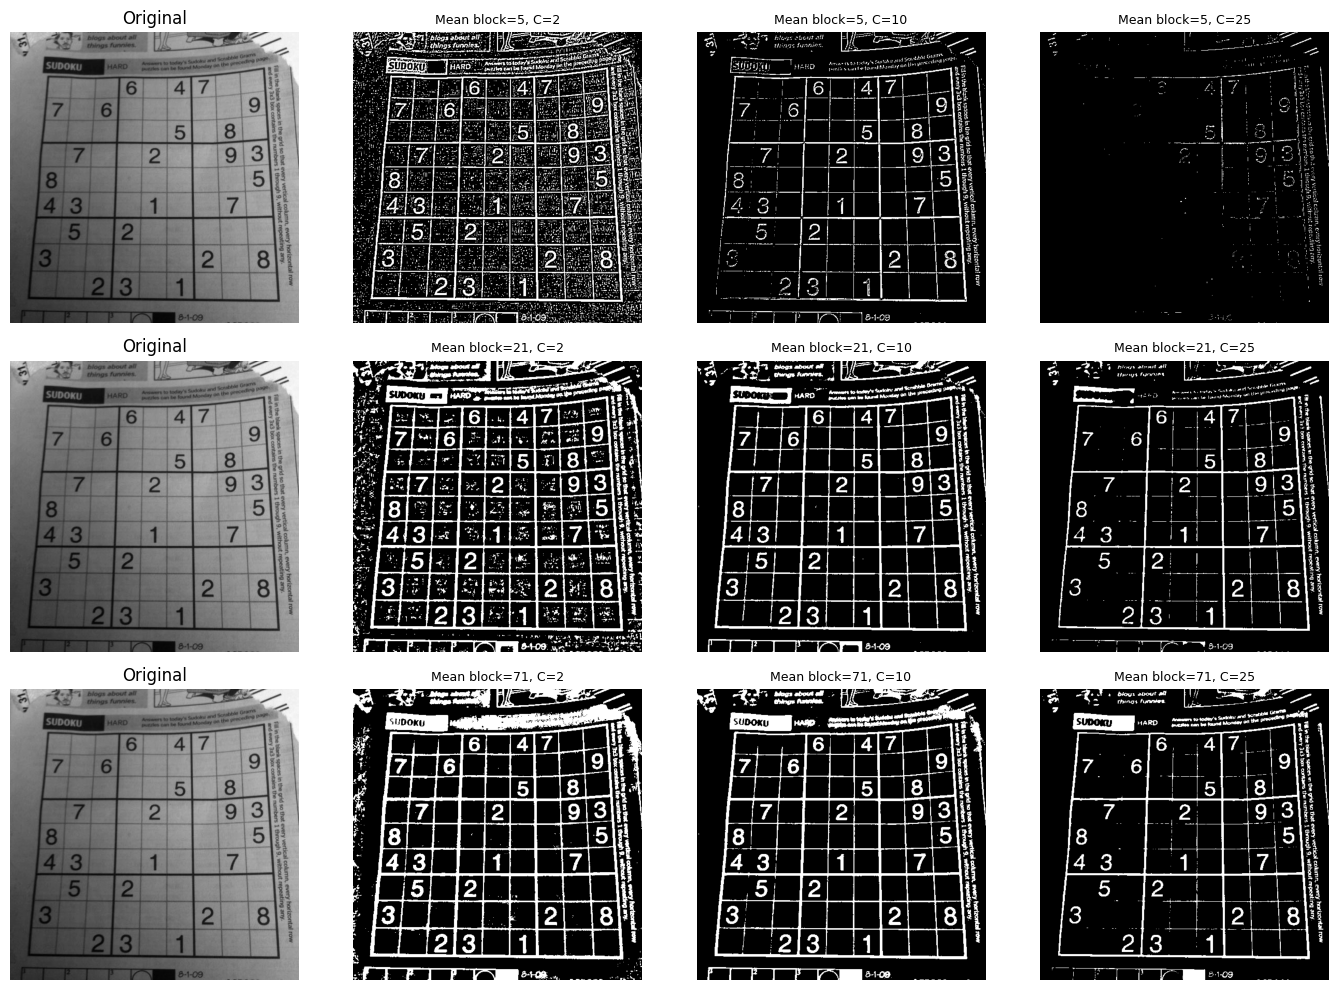

Gaussian block=  5 C= 2  white pixels =  18.2%
Gaussian block=  5 C=10  white pixels =   4.9%
Gaussian block=  5 C=25  white pixels =   0.2%
Gaussian block= 21 C= 2  white pixels =  23.8%
Gaussian block= 21 C=10  white pixels =  14.0%
Gaussian block= 21 C=25  white pixels =   7.2%
Gaussian block= 71 C= 2  white pixels =  23.3%
Gaussian block= 71 C=10  white pixels =  17.3%
Gaussian block= 71 C=25  white pixels =  10.9%


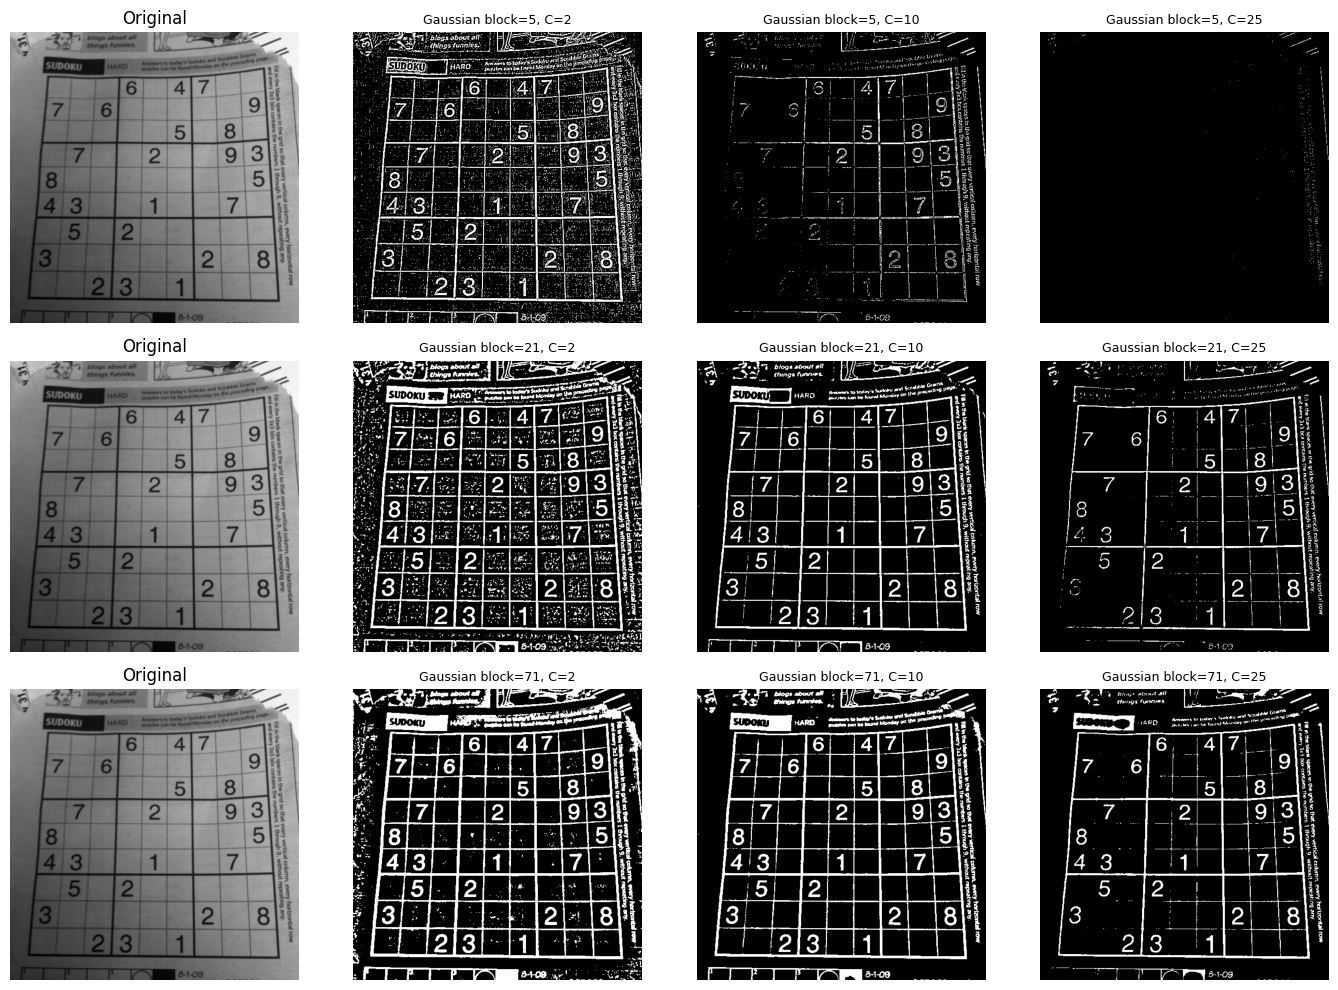

In [ ]:
blocks = [5, 21, 71]
Cs = [2, 10, 25]
methods = {"Mean": cv2.ADAPTIVE_THRESH_MEAN_C, "Gaussian": cv2.ADAPTIVE_THRESH_GAUSSIAN_C}

for name, m in methods.items():
    fig, axes = plt.subplots(len(blocks), len(Cs) + 1, figsize=(14, 10))
    for r, b in enumerate(blocks):
        axes[r, 0].imshow(gray, cmap="gray"); axes[r, 0].set_title("Original"); axes[r, 0].axis("off")
        for c, C in enumerate(Cs):
            res = cv2.adaptiveThreshold(gray, 255, m, cv2.THRESH_BINARY_INV, b, C)
            print(f"{name:8s} block={b:3d} C={C:2d}  white pixels = {100 * (res > 0).mean():5.1f}%")
            axes[r, c + 1].imshow(res, cmap="gray")
            axes[r, c + 1].set_title(f"{name} block={b}, C={C}", fontsize=9)
            axes[r, c + 1].axis("off")
    plt.tight_layout()
    plt.savefig(f"outputs/task02_{name.lower()}.png", dpi=130)
    plt.show()

## Required analysis
1. **Neighbourhood too small** – sees only a few pixels, so thick strokes break into hollow/broken characters and noise is amplified.
2. **Neighbourhood too large** – behaves like a global threshold again; uneven lighting is not removed and thin text can be lost.
3. **C increased** – threshold moves further from the local average, so noise disappears but thin/faint strokes disappear too.
4. **Cleanest combination** – medium blockSize (≈ 15–25) with medium C (≈ 8–12), e.g. block=21, C=10.
5. **Better method** – Gaussian is usually smoother/cleaner (nearby pixels weigh more); Mean is blockier and noisier.

# Task 3 — Quality-Control System Using Otsu's Thresholding

## 1. Convert to grayscale

In [ ]:
img = load("coins.jpg")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

## 2–6. Histogram + Otsu on three preprocessing variants
The threshold argument is `0` — Otsu finds it automatically.

Original gray          -> Otsu threshold = 162
Gaussian blur (5x5)    -> Otsu threshold = 162
Contrast x1.5          -> Otsu threshold = 194


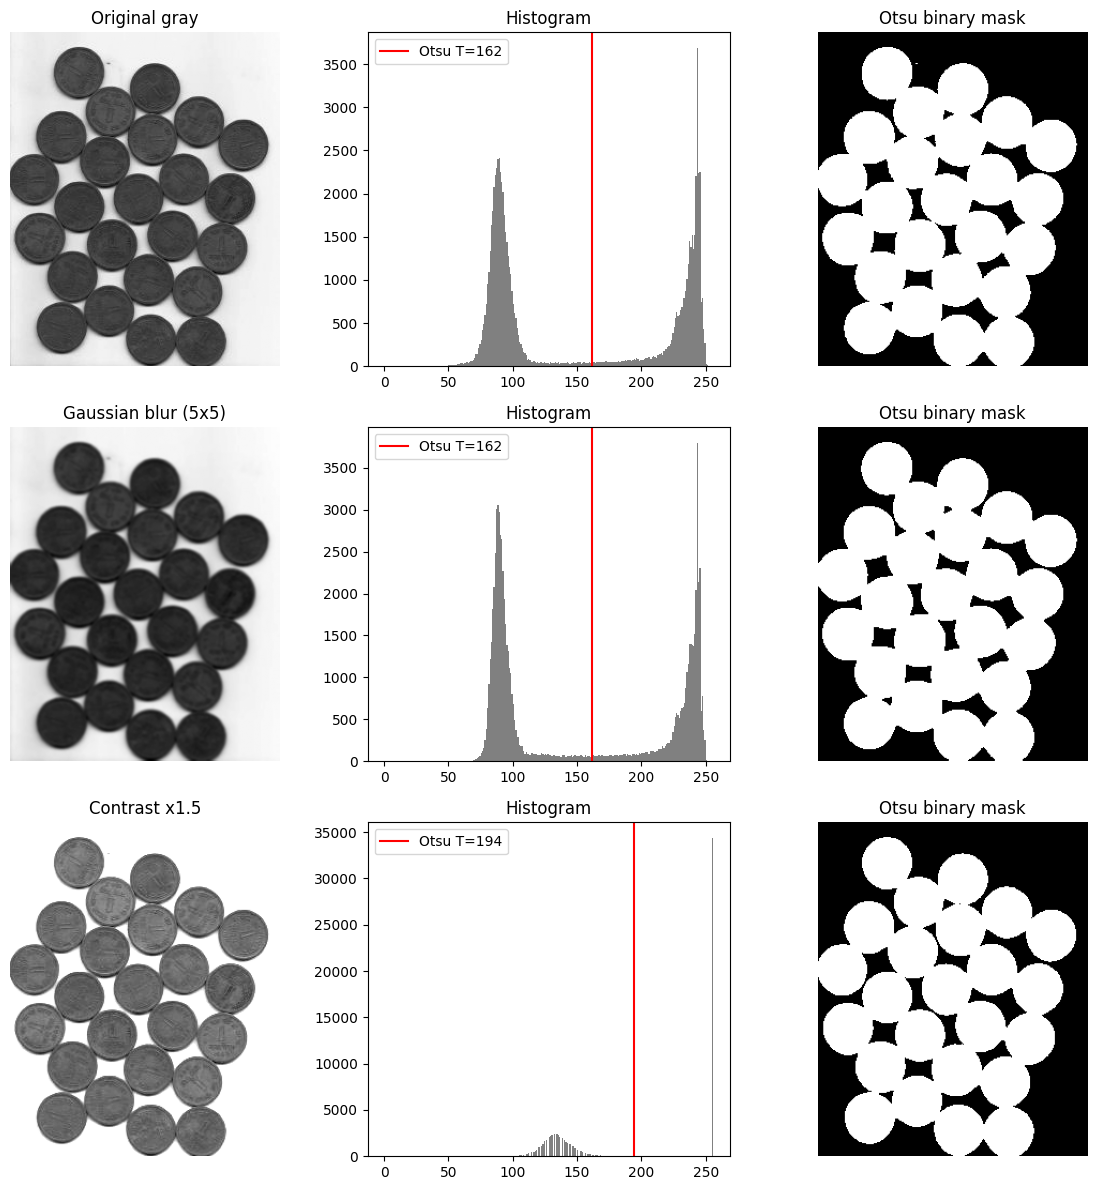

In [ ]:
variants = {
    "Original gray": gray,
    "Gaussian blur (5x5)": cv2.GaussianBlur(gray, (5, 5), 0),
    "Contrast x1.5": cv2.convertScaleAbs(gray, alpha=1.5, beta=0),
}

fig, axes = plt.subplots(len(variants), 3, figsize=(12, 4 * len(variants)))
for i, (name, g) in enumerate(variants.items()):
    t, mask = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    print(f"{name:22s} -> Otsu threshold = {t:.0f}")
    axes[i, 0].imshow(g, cmap="gray"); axes[i, 0].set_title(name); axes[i, 0].axis("off")
    axes[i, 1].hist(g.ravel(), bins=256, range=(0, 256), color="gray")
    axes[i, 1].axvline(t, color="r", label=f"Otsu T={t:.0f}"); axes[i, 1].legend(); axes[i, 1].set_title("Histogram")
    axes[i, 2].imshow(mask, cmap="gray"); axes[i, 2].set_title("Otsu binary mask"); axes[i, 2].axis("off")
    if i == 0:
        cv2.imwrite("outputs/task03_otsu_mask.png", mask)
plt.tight_layout()
plt.savefig("outputs/task03_result.png", dpi=130)
plt.show()

## Question
**Why is Otsu useful when the programmer does not know the correct threshold beforehand?**  
Otsu tests every gray level and picks the one that minimises the within-class variance of object vs background (equivalently maximises between-class variance). It assumes a roughly bimodal histogram, so no manual guessing per image is needed and it adapts when brightness/contrast changes (note the threshold moves with the contrast change above).

# Task 4 — Sorting Objects by Color (HSV)

In [ ]:
img = load("smarties.png")
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)   # OpenCV ranges: H 0-179, S 0-255, V 0-255

## Two masks
* **Restrictive:** very narrow hue band with S and V ≥ 250.
* **Final:** green hue band 40–85, S ≥ 80, V ≥ 60.

In [ ]:
lower_bad, upper_bad = np.array([66, 250, 250]), np.array([68, 255, 255])
lower, upper = np.array([40, 80, 60]), np.array([85, 255, 255])

mask_bad = cv2.inRange(hsv, lower_bad, upper_bad)
mask = cv2.inRange(hsv, lower, upper)
extracted = cv2.bitwise_and(img, img, mask=mask)

print("Restrictive mask pixels:", int(np.count_nonzero(mask_bad)))
print("Final mask pixels      :", int(np.count_nonzero(mask)))

Restrictive mask pixels: 2106
Final mask pixels      : 5362


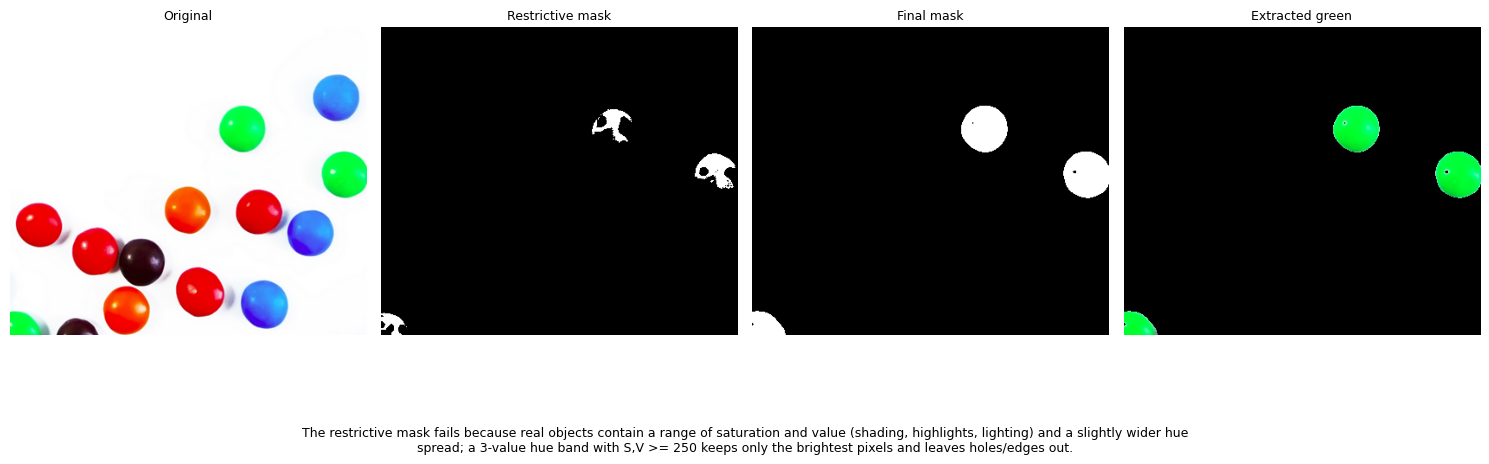

True

In [ ]:
caption = ("The restrictive mask fails because real objects contain a range of saturation and value (shading, highlights, lighting) "
           "and a slightly wider hue spread; a 3-value hue band with S,V >= 250 keeps only the brightest pixels and leaves holes/edges out.")
show_row([img, mask_bad, mask, extracted],
         ["Original", "Restrictive mask", "Final mask", "Extracted green"],
         "task04_result.png", caption, figsize=(15, 5))
cv2.imwrite("outputs/task04_final_mask.png", mask)
cv2.imwrite("outputs/task04_extracted.png", extracted)

# Task 5 — Detecting the Boundary of a Manufactured Part (Canny)

In [ ]:
img = load("smarties.png")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (5, 5), 1.4)   # reduce noise before gradient computation

## Three (low, high) pairs — low fixed, high increased
Hysteresis: pixels above **high** are strong edges; pixels between **low** and **high** are kept only if connected to a strong edge; pixels below **low** are discarded.

low=50, high=100: edge pixels = 3264
low=50, high=200: edge pixels = 2945
low=50, high=300: edge pixels = 2688


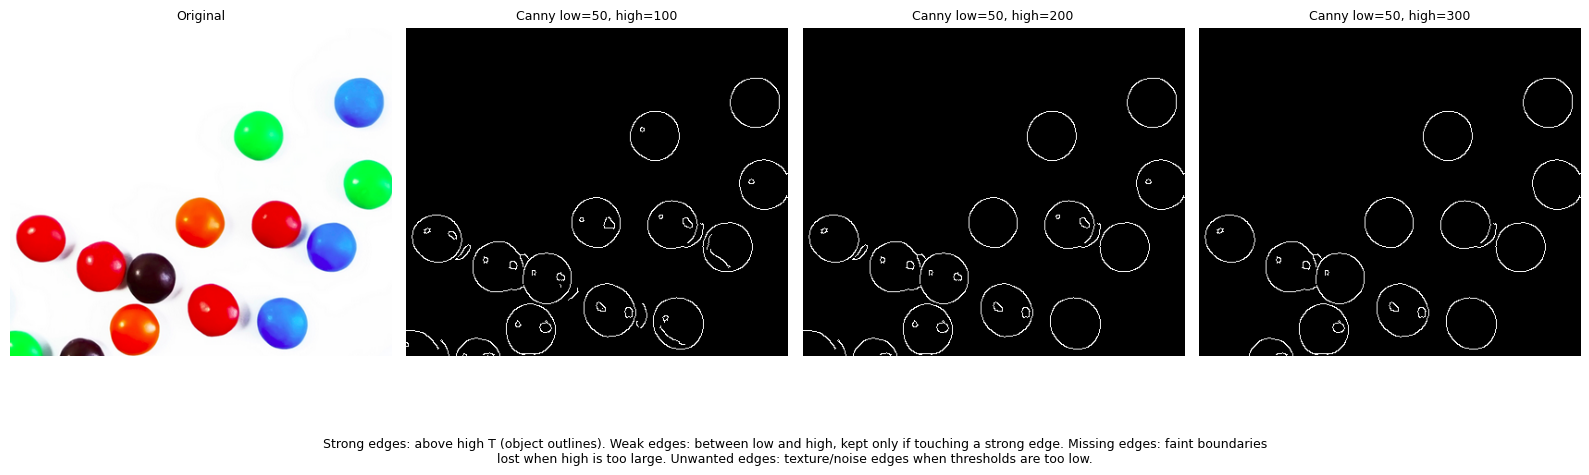

True

In [ ]:
pairs = [(50, 100), (50, 200), (50, 300)]
results = [cv2.Canny(blur, lo, hi) for lo, hi in pairs]
for (lo, hi), r in zip(pairs, results):
    print(f"low={lo}, high={hi}: edge pixels = {(r > 0).sum()}")

caption = ("Strong edges: above high T (object outlines). Weak edges: between low and high, kept only if touching a strong edge. "
           "Missing edges: faint boundaries lost when high is too large. Unwanted edges: texture/noise edges when thresholds are too low.")
show_row([img] + results, ["Original"] + [f"Canny low={lo}, high={hi}" for lo, hi in pairs],
         "task05_result.png", caption, figsize=(16, 5))
cv2.imwrite("outputs/task05_final_edges.png", results[1])

## How the thresholds change the result
* **Increase high (low fixed):** fewer edge pixels — weak/low-contrast and unconnected edges vanish, the outline becomes cleaner but may break.
* **Decrease low:** weak edges get linked to strong ones, giving more continuous boundaries but also more unwanted edges (shadows, specular highlights).
* **Good choice here:** (50, 200) — object outlines intact with little clutter.

# Task 6 — Segmenting a Region Inside a Medical Image (Region Growing)

In [ ]:
gray = load("brain_mri.png", cv2.IMREAD_GRAYSCALE)
gray_blur = cv2.GaussianBlur(gray, (5, 5), 0)   # smooth so noise does not stop the growth

## Region-growing function
A neighbour joins the region if `|pixel − seed intensity| ≤ threshold`.

In [ ]:
def region_grow(img, seed, thresh):
    h, w = img.shape
    mask = np.zeros((h, w), np.uint8)
    seed_val = int(img[seed])
    q = deque([seed]); mask[seed] = 255
    while q:
        r, c = q.popleft()
        for dr in (-1, 0, 1):
            for dc in (-1, 0, 1):
                nr, nc = r + dr, c + dc
                if 0 <= nr < h and 0 <= nc < w and mask[nr, nc] == 0:
                    if abs(int(img[nr, nc]) - seed_val) <= thresh:
                        mask[nr, nc] = 255
                        q.append((nr, nc))
    return mask

## Parameter study: 3 thresholds × 2 seeds

Seed A (tumour) (165, 105) intensity = 220
Seed B (healthy tissue) (140, 220) intensity = 133
Seed A (tumour), thresh=25: region size = 1636 px
Seed A (tumour), thresh=45: region size = 2088 px
Seed A (tumour), thresh=70: region size = 3442 px
Seed B (healthy tissue), thresh=25: region size = 19199 px
Seed B (healthy tissue), thresh=45: region size = 24520 px


Seed B (healthy tissue), thresh=70: region size = 30671 px


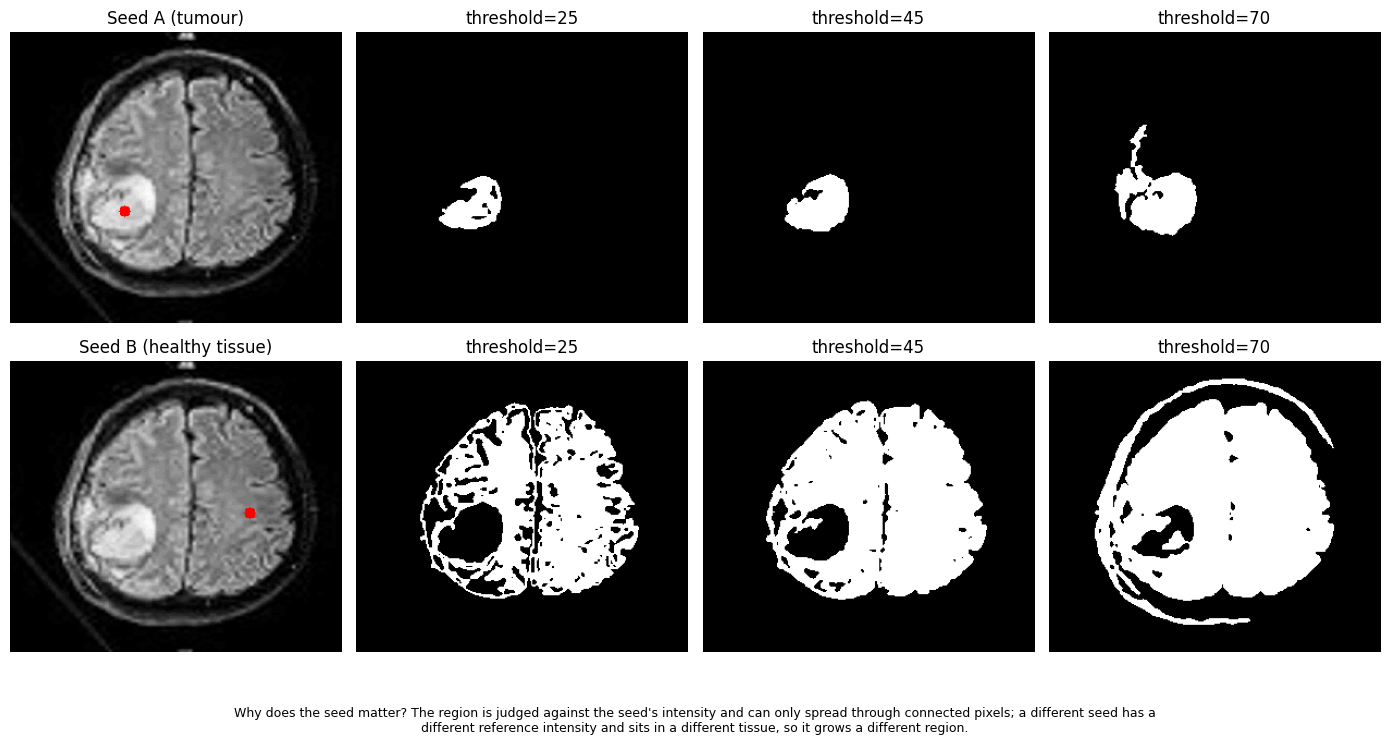

In [ ]:
seeds = {"Seed A (tumour)": (165, 105), "Seed B (healthy tissue)": (140, 220)}
thresholds = [25, 45, 70]
for name, s in seeds.items():
    print(name, s, "intensity =", gray_blur[s])

fig, axes = plt.subplots(len(seeds), len(thresholds) + 1, figsize=(14, 7.5))
for i, (name, s) in enumerate(seeds.items()):
    ov = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB); cv2.circle(ov, (s[1], s[0]), 5, (255, 0, 0), -1)
    axes[i, 0].imshow(ov); axes[i, 0].set_title(name); axes[i, 0].axis("off")
    for j, t in enumerate(thresholds):
        m = region_grow(gray_blur, s, t)
        print(f"{name}, thresh={t}: region size = {(m > 0).sum()} px")
        axes[i, j + 1].imshow(m, cmap="gray"); axes[i, j + 1].set_title(f"threshold={t}"); axes[i, j + 1].axis("off")
        if i == 0 and t == 45:
            cv2.imwrite("outputs/task06_final_mask.png", m)
fig.text(0.5, 0.01, textwrap.fill("Why does the seed matter? The region is judged against the seed's intensity and can only spread through connected pixels; "
         "a different seed has a different reference intensity and sits in a different tissue, so it grows a different region.", 150), ha="center", fontsize=9)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.savefig("outputs/task06_result.png", dpi=130)
plt.show()

## Analysis
* **Threshold:** 25 → only the brightest core of the tumour; 45 → the whole bright tumour region on the left hemisphere; 70 → starts to leak into the surrounding bright oedema/tissue.
* **Seed A (tumour, ≈220) vs Seed B (healthy tissue, ≈130):** seed A grows a compact tumour mask; seed B grows a large, fragmented region of normal brain tissue because the intensities of grey/white matter are similar and noisy.
* **Why can the seed change the region significantly?** Region growing is relative to the seed's intensity and only spreads through connected pixels. Seeds in different tissues have different reference intensities and sit in different connected areas, so the grown regions are completely different. Even a noisy single-pixel seed shifts the reference value (which is why the image is blurred first).

# Task 7 — Separating Touching Coins (Marker-Based Watershed)
**Image:** `images/coins.jpg`

In [ ]:
img = load("coins.jpg")

## Stages 1–2: Preprocessing + Thresholding (Otsu, coins are darker → INV)

In [ ]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (5, 5), 0)
_, thresh = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

## Stages 3–4: Noise removal (opening) + Sure background (dilate)

In [ ]:
kernel = np.ones((3, 3), np.uint8)
opening = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=2)
sure_bg = cv2.dilate(opening, kernel, iterations=3)

## Stages 5–6: Distance transform + Sure foreground (50 % of max distance)

In [ ]:
dist = cv2.distanceTransform(opening, cv2.DIST_L2, 5)
DIST_FRACTION = 0.5
_, sure_fg = cv2.threshold(dist, DIST_FRACTION * dist.max(), 255, 0)
sure_fg = np.uint8(sure_fg)

## Stages 7–8: Unknown region + Marker labelling

In [ ]:
unknown = cv2.subtract(sure_bg, sure_fg)
n, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1               # background becomes 1 instead of 0
markers[unknown == 255] = 0         # 0 = unknown, to be decided by watershed

## Stages 9–10: Watershed + Boundary visualisation

In [ ]:
result = img.copy()
markers = cv2.watershed(result, markers)
result[markers == -1] = (0, 0, 255)  # boundaries are -1 -> draw red
print("Foreground markers (coins found):", n - 1)

Foreground markers (coins found): 24


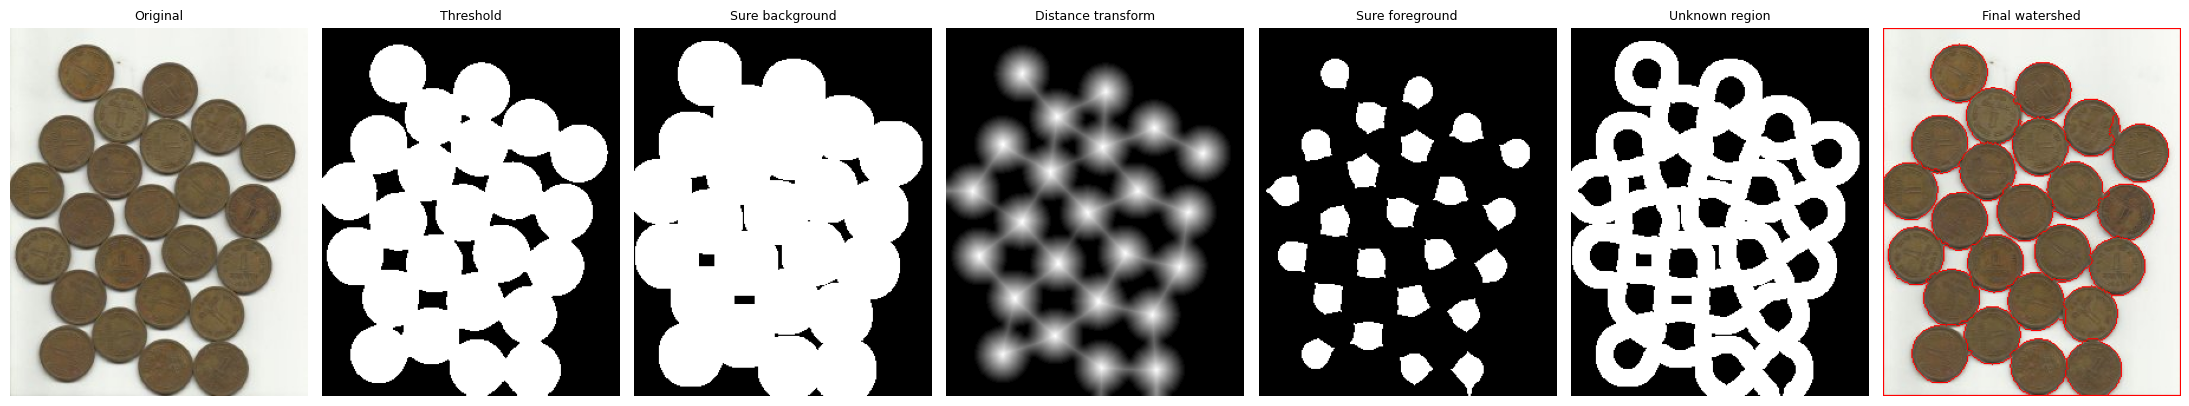

True

In [ ]:
dist_vis = cv2.normalize(dist, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
show_row([img, thresh, sure_bg, dist_vis, sure_fg, unknown, result],
         ["Original", "Threshold", "Sure background", "Distance transform", "Sure foreground", "Unknown region", "Final watershed"],
         "task07_result.png", figsize=(22, 4.5))
cv2.imwrite("outputs/task07_final_watershed.png", result)

## Visual inspection
Every touching coin gets its own red boundary, so counting regions now gives the correct count (24 coins).

# Task 8 — Tuning Watershed for Difficult Object Separation

In [ ]:
img = load("coins.jpg")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (5, 5), 0)
_, thresh = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
kernel = np.ones((3, 3), np.uint8)
opening = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=2)
sure_bg = cv2.dilate(opening, kernel, iterations=3)
dist = cv2.distanceTransform(opening, cv2.DIST_L2, 5)
print("Max distance value:", round(dist.max(), 1))

Max distance value: 24.0


In [ ]:
def run_watershed(fraction):
    _, sure_fg = cv2.threshold(dist, fraction * dist.max(), 255, 0)
    sure_fg = np.uint8(sure_fg)
    unknown = cv2.subtract(sure_bg, sure_fg)
    n, markers = cv2.connectedComponents(sure_fg)
    markers = markers + 1
    markers[unknown == 255] = 0
    res = img.copy()
    markers = cv2.watershed(res, markers)
    res[markers == -1] = (0, 0, 255)
    regions = len(np.unique(markers)) - 2      # minus background(1) and boundary(-1)
    return n - 1, regions, res

## Four experiments

In [ ]:
fractions = [0.2, 0.4, 0.6, 0.99]
rows, outs, titles = [], [], []
for k, f in enumerate(fractions, 1):
    fg, regions, res = run_watershed(f)
    rows.append([k, f"{f} x max = {f * dist.max():.1f}", fg, regions])
    outs.append(res); titles.append(f"Exp {k}: {f}*max ({fg} markers)")

table = pd.DataFrame(rows, columns=["Experiment", "Distance Threshold", "Foreground", "Regions"])
table["Observed Result"] = ["All coins merged into one marker (too low)",
                            "Only 7 markers - many coins still merged",
                            "24 markers - one per coin (correct)",
                            "Markers shrink to tiny cores; some coins lost (too high)"]
table.to_csv("outputs/task08_table.csv", index=False)
table

,Experiment,Distance Threshold,Foreground,Regions,Observed Result
0,1,0.2 x max = 4.8,1,1,All coins merged into one marker (too low)
1,2,0.4 x max = 9.6,7,7,Only 7 markers - many coins still merged
2,3,0.6 x max = 14.4,24,24,24 markers - one per coin (correct)
3,4,0.99 x max = 23.8,20,20,Markers shrink to tiny cores; some coins lost ...


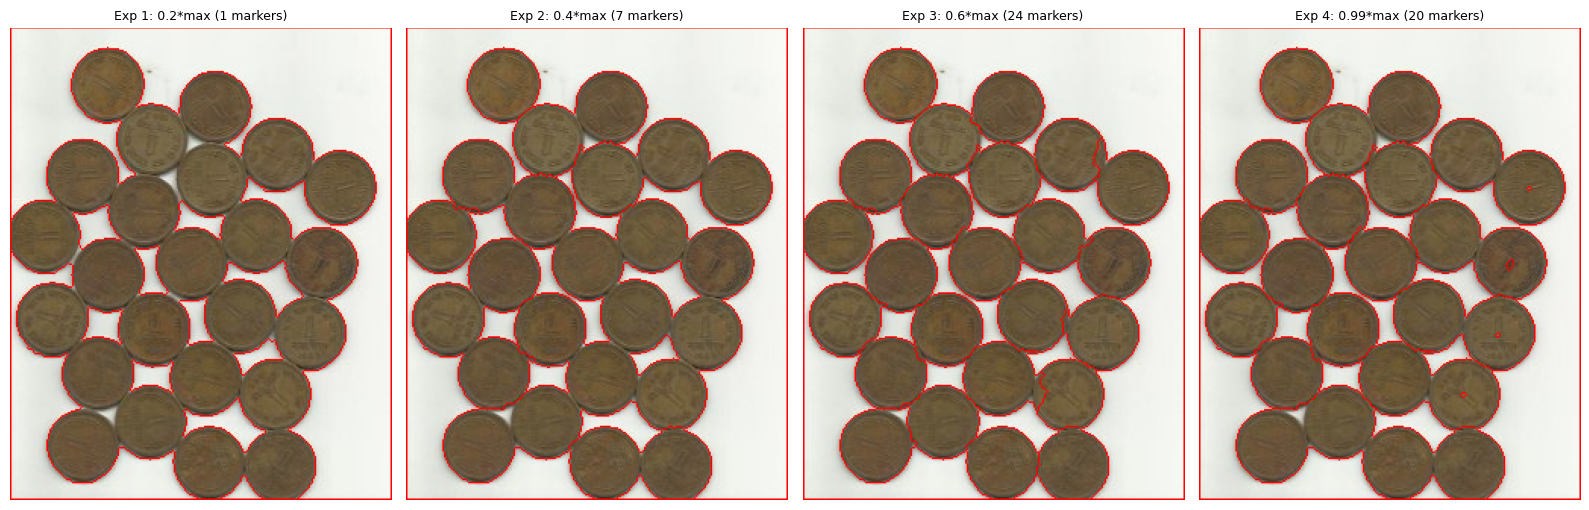

In [ ]:
show_row(outs, titles, "task08_result.png", figsize=(16, 5.5))

## Best parameter range
A distance threshold of roughly **0.5 – 0.9 × max distance** gives one marker per coin (24). Below ≈ 0.35 the sure-foreground blobs of touching coins stay connected (merged objects); at ≈ 1.0 the cores become too small and some coins disappear.

*Note: the 'Observed Result' column is written from the table above — re-check it if you change the fractions.*

# Task 9 — Segmenting an Image Using K-Means

In [ ]:
img = load("dog.jpeg")
h, w = img.shape[:2]
print("Image size:", h, "x", w)

Image size: 350 x 233


## Steps 2–3: pixel feature vectors + float32

In [ ]:
pixels = img.reshape((-1, 3)).astype(np.float32)   # (num_pixels, 3) BGR vectors
print(pixels.shape, pixels.dtype)

(81550, 3) float32


## Steps 4–5: K-Means for K = 2, 4, 6 and reconstruction

In [ ]:
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 1.0)
outs, titles = [], []
for K in [2, 4, 6]:
    _, labels, centers = cv2.kmeans(pixels, K, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)
    centers = np.uint8(centers)
    seg = centers[labels.flatten()].reshape((h, w, 3))
    mse = np.mean((img.astype(np.float32) - seg.astype(np.float32)) ** 2)
    sizes = np.bincount(labels.flatten(), minlength=K) / labels.size * 100
    print(f"K={K}: unique colours = {len(np.unique(seg.reshape(-1, 3), axis=0))}, error (MSE) = {mse:.1f}")
    for i, c in enumerate(centers):
        print(f"    cluster {i}: BGR={c.tolist()}  covers {sizes[i]:.1f}% of pixels")
    outs.append(seg); titles.append(f"K={K}")
    cv2.imwrite(f"outputs/task09_kmeans_K{K}.png", seg)

K=2: unique colours = 2, error (MSE) = 513.8
    cluster 0: BGR=[142, 147, 180]  covers 21.2% of pixels
    cluster 1: BGR=[59, 66, 90]  covers 78.8% of pixels


K=4: unique colours = 4, error (MSE) = 194.2
    cluster 0: BGR=[183, 182, 200]  covers 8.3% of pixels
    cluster 1: BGR=[53, 56, 75]  covers 50.4% of pixels
    cluster 2: BGR=[116, 125, 166]  covers 13.3% of pixels
    cluster 3: BGR=[70, 84, 116]  covers 28.0% of pixels


K=6: unique colours = 6, error (MSE) = 130.9
    cluster 0: BGR=[105, 118, 161]  covers 9.3% of pixels
    cluster 1: BGR=[52, 54, 70]  covers 38.4% of pixels
    cluster 2: BGR=[195, 195, 209]  covers 5.0% of pixels
    cluster 3: BGR=[77, 92, 125]  covers 15.9% of pixels
    cluster 4: BGR=[151, 150, 184]  covers 7.2% of pixels
    cluster 5: BGR=[59, 70, 98]  covers 24.1% of pixels


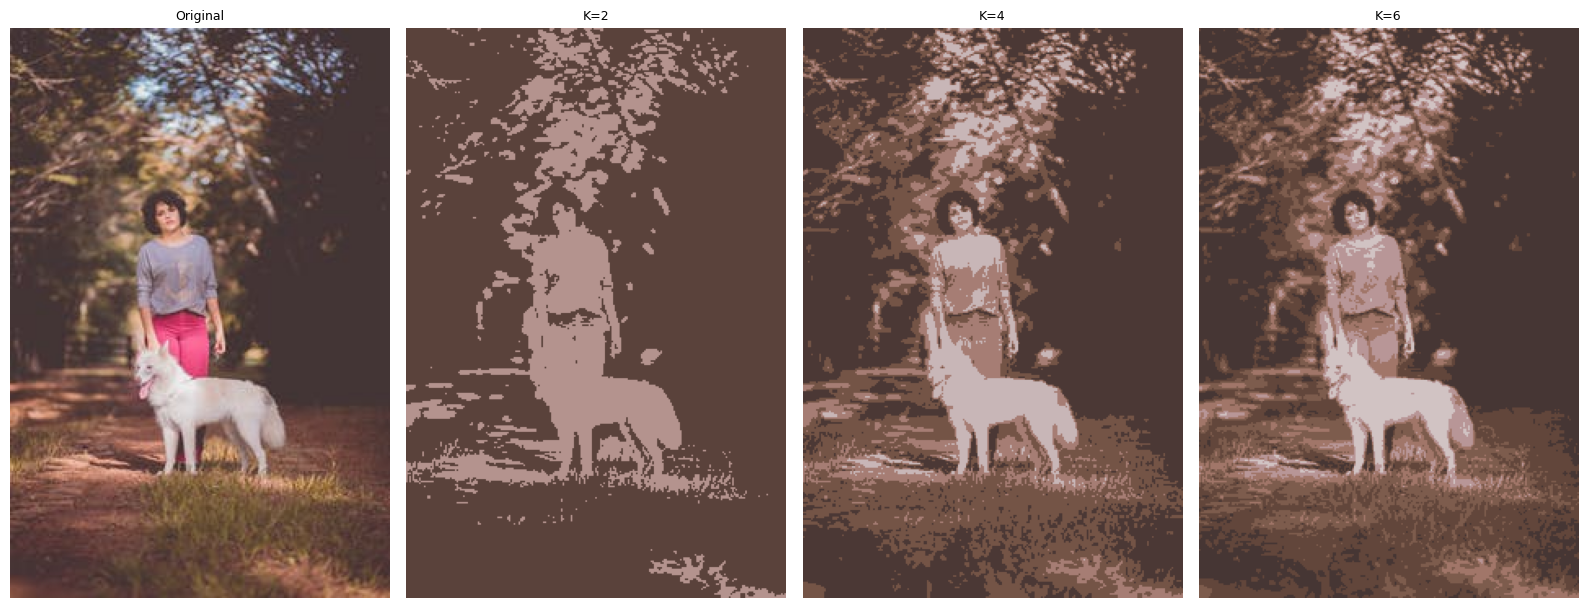

In [ ]:
show_row([img] + outs, ["Original"] + titles, "task09_result.png", figsize=(16, 6))

## Record for each K
| K | Visual difference from original | Colour simplification | Major regions |
|---|---|---|---|
| 2 | Flat two-tone image; only the bright subjects and light foliage separate from the dark background | Extreme (2 colours) | Dark shadows/trees vs light areas (white dog, top, bright foliage, path) |
| 4 | Woman, white dog, path and tree canopy become recognisable; colour (pink trousers, green grass) is lost | Strong | Dark trees, mid-brown path/grass, light foliage, white dog and grey top |
| 6 | Closest to the original, posterised; extra shading in foliage, grass and clothing | Moderate | Adds intermediate tones for sunlit grass, path highlights and dog fur shading |

Lower MSE (printed above) means the segmented image is closer to the original; larger K = more detail but less simplification.

*Edit this table to match what you see in your own run.*

# Task 10 — Design a Segmentation System for an Unknown Image

In [ ]:
img = load("smarties.png")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

## Method 1 — Otsu
Assumes a bimodal intensity histogram (objects vs plain white background).

In [ ]:
t, otsu = cv2.threshold(cv2.GaussianBlur(gray, (5, 5), 0), 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
n_otsu = cv2.connectedComponents(cv2.morphologyEx(otsu, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8)))[0] - 1
print(f"Otsu threshold = {t:.0f}, connected object regions = {n_otsu}")

Otsu threshold = 177, connected object regions = 14


## Method 2 — HSV colour thresholding (green)
Assumes the target object has a distinct hue.

In [ ]:
hsv_mask = cv2.inRange(hsv, np.array([40, 80, 60]), np.array([85, 255, 255]))
n_hsv = cv2.connectedComponents(cv2.morphologyEx(hsv_mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8)))[0] - 1
print("HSV green mask regions =", n_hsv)

HSV green mask regions = 3


## Method 3 — K-Means (K = 6)
Assumes the image is made of a few dominant colours.

In [ ]:
pix = img.reshape((-1, 3)).astype(np.float32)
crit = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 1.0)
_, lab, cen = cv2.kmeans(pix, 6, None, crit, 5, cv2.KMEANS_PP_CENTERS)
kmeans = np.uint8(cen)[lab.flatten()].reshape(img.shape)
print("K-Means colours:", len(np.unique(kmeans.reshape(-1, 3), axis=0)))

K-Means colours: 6


## Final comparison  (Original | Method 1 | Method 2 | Method 3)

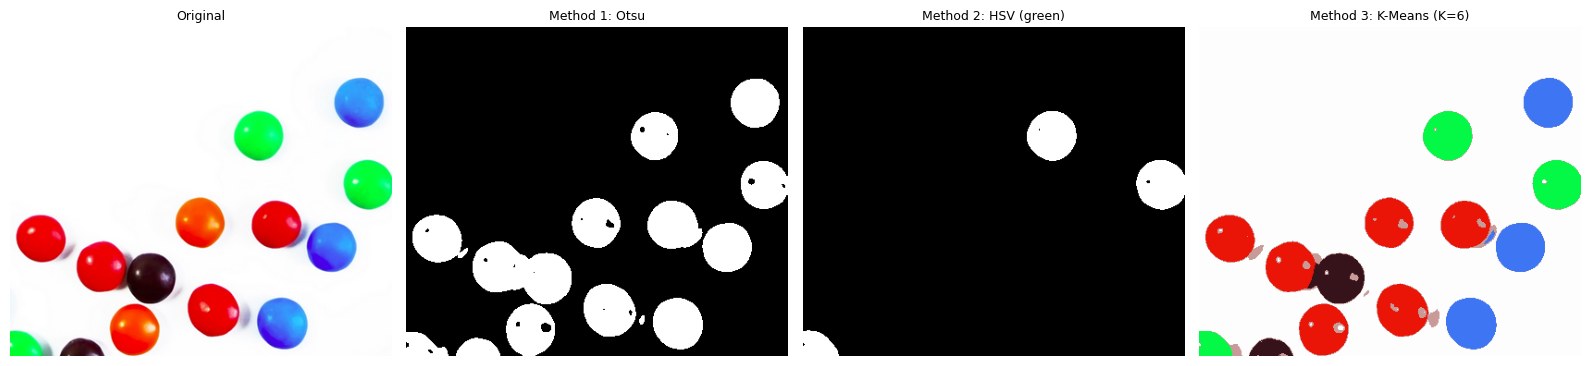

In [ ]:
show_row([img, otsu, hsv_mask, kmeans],
         ["Original", "Method 1: Otsu", "Method 2: HSV (green)", "Method 3: K-Means (K=6)"],
         "task10_result.png", figsize=(16, 5))

## Analysis per method
| | Assumption | Successfully identifies | Incorrectly segments | Most influential parameter |
|---|---|---|---|---|
| **Otsu** | Bimodal gray levels (objects darker than white background) | All the smarties as foreground blobs | Gives no colour information; highlights create small holes; touching smarties can merge | Threshold value / blur size |
| **HSV** | Target has a distinct hue | Green smarties only | All other colours ignored; shadowed/dark pixels of green smarties may be missed | Hue range (then S/V lower bounds) |
| **K-Means** | Image has a few dominant colours | Red, blue, green, brown regions and the white background in one step | No object separation; similar colours (orange vs red) can merge | K (number of clusters) |

## Technical conclusion
**K-Means** produced the most meaningful regions for this image: in one step it separated the colour classes (red, blue, green, dark brown) from the white background. This works because the image consists of a small number of well-separated, saturated colours on a plain background. Otsu found the objects but not their colour, and HSV thresholding only isolates one colour at a time. *(Confirm against your own outputs before submitting.)*